# Módulo 2 — Regla del Trapecio (prototipo en Python)

**Proyecto:** Cálculo Integral Interactivo · Matemáticas II · UTP

Implementamos la regla del trapecio **desde cero** con NumPy y comprobamos los ejemplos del módulo 2 de la plataforma.

$$T_n=\frac{\Delta x}{2}\Big[f(x_0)+2f(x_1)+\cdots+2f(x_{n-1})+f(x_n)\Big],\qquad \Delta x=\frac{b-a}{n}$$

## 1. Preparación

In [1]:
# --- Bibliotecas que usaremos ---
import numpy as np                 # cálculo numérico con arreglos
import matplotlib.pyplot as plt    # gráficas
import sympy as sp                 # matemática simbólica: SOLO para el valor exacto y para verificar
                                   # (los algoritmos numéricos los escribimos nosotros desde cero)

x = sp.symbols("x")                # símbolo matemático "x" para SymPy

def preparar(expr, a, b):
    """Convierte una expresión de SymPy en (f_numpy, valor_exacto).
    - f_numpy: función que acepta arreglos de NumPy.
    - valor_exacto: integral definida exacta (Teorema Fundamental del Cálculo), como número decimal."""
    f = sp.lambdify(x, expr, "numpy")
    exacto = float(sp.integrate(expr, (x, a, b)))
    return f, exacto

## 2. Implementación desde cero
Los extremos $f(x_0)$ y $f(x_n)$ se cuentan **una vez**; los puntos interiores, **dos veces** (porque pertenecen a dos trapecios vecinos).

In [2]:
def trapecio(f, a, b, n):
    """Regla del trapecio con n subintervalos."""
    xs = np.linspace(a, b, n + 1)            # los n+1 nodos x0, x1, ..., xn
    ys = f(xs)                               # alturas en cada nodo
    dx = (b - a) / n
    # extremos una vez + interiores dos veces, todo multiplicado por dx/2
    return dx / 2 * (ys[0] + 2 * np.sum(ys[1:-1]) + ys[-1])

def riemann(f, a, b, n, tipo="izq"):
    """(Del cuaderno 1) Suma de Riemann; la usamos para comparar."""
    dx = (b - a) / n
    i = np.arange(n)
    puntos = {"izq": a + i * dx, "der": a + (i + 1) * dx, "medio": a + (i + 0.5) * dx}[tipo]
    return np.sum(f(puntos)) * dx

## 3. Ejemplo 1 del módulo: $\int_0^2 x^2\,dx$ con $n=4$

In [3]:
f1, exacto1 = preparar(x**2, 0, 2)
T = trapecio(f1, 0, 2, 4)
print(f"T4 = {T:.5f}   (a mano: 2.75)")
print(f"Exacto = {exacto1:.5f}   error = {abs(T - exacto1):.5f}   (a mano: 0.0833)")
print("Sobreestima" if T > exacto1 else "Subestima")
assert np.isclose(T, 2.75)
print("✔ Coincide con el ejemplo 1 del módulo 2")

T4 = 2.75000   (a mano: 2.75)
Exacto = 2.66667   error = 0.08333   (a mano: 0.0833)
Sobreestima
✔ Coincide con el ejemplo 1 del módulo 2


## 4. Ejemplo 2 del módulo: $\int_1^3 \dfrac{1}{x}\,dx$ con $n=4$

In [4]:
f2, exacto2 = preparar(1 / x, 1, 3)
T = trapecio(f2, 1, 3, 4)
print(f"T4 = {T:.5f}   (a mano: 67/60 = {67/60:.5f})")
print(f"ln 3 = {exacto2:.5f}   error = {abs(T - exacto2):.5f}")
assert np.isclose(T, 67 / 60)
print("✔ Coincide con el ejemplo 2 del módulo 2")

T4 = 1.11667   (a mano: 67/60 = 1.11667)
ln 3 = 1.09861   error = 0.01805
✔ Coincide con el ejemplo 2 del módulo 2


## 5. Una relación útil: $T_n=\dfrac{L_n+R_n}{2}$
El trapecio es el promedio de las sumas izquierda y derecha. Lo comprobamos numéricamente.

In [5]:
L = riemann(f1, 0, 2, 4, "izq")
R = riemann(f1, 0, 2, 4, "der")
print(f"(L4 + R4) / 2 = {(L + R) / 2:.5f}")
print(f"T4            = {trapecio(f1, 0, 2, 4):.5f}")
assert np.isclose((L + R) / 2, trapecio(f1, 0, 2, 4))
print("✔ Son iguales")

(L4 + R4) / 2 = 2.75000
T4            = 2.75000
✔ Son iguales


## 6. Visualización de los trapecios

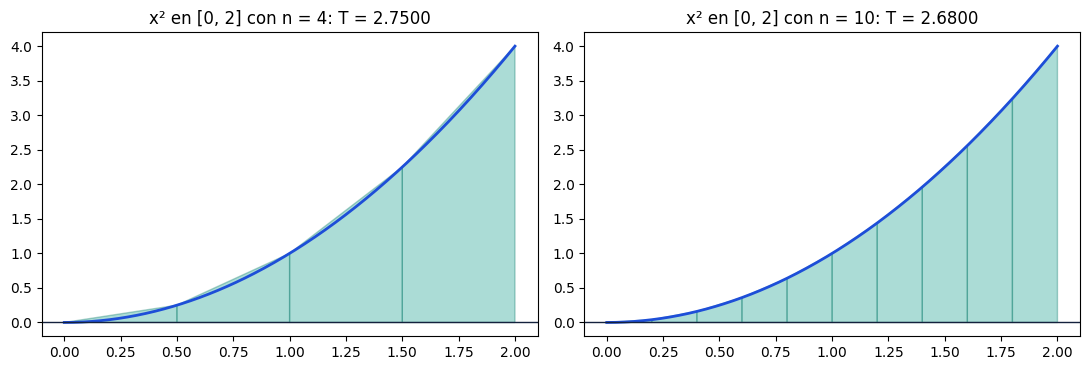

In [6]:
def dibujar_trapecios(f, a, b, n, ax):
    xs = np.linspace(a, b, 400)
    ax.plot(xs, f(xs), lw=2, color="#1d4ed8")
    nodos = np.linspace(a, b, n + 1)
    for x0, x1 in zip(nodos[:-1], nodos[1:]):
        # Cada trapecio: (x0,0) -> (x0,f(x0)) -> (x1,f(x1)) -> (x1,0)
        ax.fill([x0, x0, x1, x1], [0, f(x0), f(x1), 0],
                alpha=0.35, color="#0f9d8a", edgecolor="#0b7a6b")
    ax.axhline(0, color="#14213d", lw=1)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(ejes, [4, 10]):
    dibujar_trapecios(f1, 0, 2, n, ax)
    ax.set_title(f"x² en [0, 2] con n = {n}: T = {trapecio(f1, 0, 2, n):.4f}")
plt.tight_layout(); plt.show()

## 7. ¿Cómo baja el error? El orden de convergencia
Si el error es proporcional a $1/n^p$, entonces al **duplicar** $n$ el cociente $E(n)/E(2n)$ vale aproximadamente $2^p$. Calculamos $p=\log_2\big(E(n)/E(2n)\big)$.

In [7]:
f3, exacto3 = preparar(sp.exp(x), 0, 1)
ns = [2, 4, 8, 16, 32, 64, 128]
errores = [abs(trapecio(f3, 0, 1, n) - exacto3) for n in ns]

print(f"{'n':>5} | {'error':>12} | {'p estimado':>10}")
print("-" * 34)
for k, n in enumerate(ns):
    p = np.log2(errores[k - 1] / errores[k]) if k > 0 else float("nan")
    print(f"{n:>5} | {errores[k]:>12.3e} | {p:>10.3f}")

    n |        error | p estimado
----------------------------------
    2 |    3.565e-02 |        nan
    4 |    8.940e-03 |      1.996
    8 |    2.237e-03 |      1.999
   16 |    5.593e-04 |      2.000
   32 |    1.398e-04 |      2.000
   64 |    3.496e-05 |      2.000
  128 |    8.740e-06 |      2.000


## Preguntas para pensar

1. ¿Qué valor de $p$ aparece en la tabla? ¿Qué significa para el error si pasas de $n=10$ a $n=20$?
2. El trapecio sobreestimó $x^2$ y $1/x$. ¿Qué tienen en común estas funciones en cuanto a su concavidad? ¿Qué esperas para $\operatorname{sen}(x)$ en $[0,\pi]$? Compruébalo con `preparar(sp.sin(x), 0, sp.pi)`.
3. **Ejercicio:** ¿para qué $n$ el error del trapecio con $e^x$ en $[0,1]$ baja de $10^{-6}$? Búscalo con un ciclo.